In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import pandas as pd

# Replace with the actual path to your CSV file in Google Drive
file_path = '/content/drive/MyDrive/NLP/olist_order_reviews_dataset.csv'

try:
    df = pd.read_csv(file_path)
    display(df.head())
except Exception as e:
    print(f"Error loading file: {e}")

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [22]:
df['review_score'].describe()

,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


In [23]:
duplicate_review_count = df.duplicated(subset=['review_id']).sum()
print(f"Number of duplicate review IDs: {duplicate_review_count}\n")

Number of duplicate review IDs: 814



In [24]:
duplicated_reviews = df[df.duplicated(subset=['review_id'], keep=False)]

unique_comments_per_id = duplicated_reviews.groupby('review_id')['review_comment_message'].nunique()

total_duplicate_ids = unique_comments_per_id.index.nunique()
same_comment_count = (unique_comments_per_id <= 1).sum()
different_comment_count = (unique_comments_per_id > 1).sum()

print(f"Total number of the unique duplicated review IDs: {total_duplicate_ids}")
print(f"Duplicated reivew ID with the same comment or both are null: {same_comment_count}")
print(f"Duplicated reivew ID with different comments: {different_comment_count}\n")

Total number of the unique duplicated review IDs: 789
Duplicated reivew ID with the same comment or both are null: 789
Duplicated reivew ID with different comments: 0



In [25]:
df.drop_duplicates(subset=['review_id'], inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 98410 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                98410 non-null  object
 1   order_id                 98410 non-null  object
 2   review_score             98410 non-null  int64 
 3   review_comment_title     11519 non-null  object
 4   review_comment_message   40668 non-null  object
 5   review_creation_date     98410 non-null  object
 6   review_answer_timestamp  98410 non-null  object
dtypes: int64(1), object(6)
memory usage: 6.0+ MB


In [26]:
duplicate_order_count = df.duplicated(subset=['order_id']).sum()
print(f"Number of duplicate order IDs: {duplicate_order_count}\n")

Number of duplicate order IDs: 243



In [27]:
duplicated_reviews = df[df.duplicated(subset=['order_id'], keep=False)]

unique_comments_per_id = duplicated_reviews.groupby('order_id')['review_comment_message'].nunique()

total_duplicate_ids = unique_comments_per_id.index.nunique()
same_comment_count = (unique_comments_per_id <= 1).sum()
different_comment_count = (unique_comments_per_id > 1).sum()

print(f"Total number of the unique duplicated review IDs: {total_duplicate_ids}")
print(f"Duplicated reivew ID with the same comment or both are null: {same_comment_count}")
print(f"Duplicated reivew ID with different comments: {different_comment_count}\n")

Total number of the unique duplicated review IDs: 243
Duplicated reivew ID with the same comment or both are null: 185
Duplicated reivew ID with different comments: 58



In [28]:
df.drop_duplicates(subset=['order_id', 'review_comment_message'], inplace=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 98273 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                98273 non-null  object
 1   order_id                 98273 non-null  object
 2   review_score             98273 non-null  int64 
 3   review_comment_title     11517 non-null  object
 4   review_comment_message   40661 non-null  object
 5   review_creation_date     98273 non-null  object
 6   review_answer_timestamp  98273 non-null  object
dtypes: int64(1), object(6)
memory usage: 6.0+ MB


In [29]:
df = df.dropna(subset=['review_comment_message'])
df = df[df['review_comment_message'].str.strip() != '']

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40634 entries, 3 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                40634 non-null  object
 1   order_id                 40634 non-null  object
 2   review_score             40634 non-null  int64 
 3   review_comment_title     9787 non-null   object
 4   review_comment_message   40634 non-null  object
 5   review_creation_date     40634 non-null  object
 6   review_answer_timestamp  40634 non-null  object
dtypes: int64(1), object(6)
memory usage: 2.5+ MB


In [30]:
titles = df['review_comment_title'].fillna('')

df['review_comment'] = (titles + ' ' + df['review_comment_message']).str.strip()

df = df.drop(columns=['review_comment_title', 'review_comment_message'])
df.head()

,review_id,order_id,review_score,review_creation_date,review_answer_timestamp,review_comment
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,2017-04-21 00:00:00,2017-04-21 22:02:06,Recebi bem antes do prazo estipulado.
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,2018-03-01 00:00:00,2018-03-02 10:26:53,Parabéns lojas lannister adorei comprar pela I...
9,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4,2018-05-22 00:00:00,2018-05-23 16:45:47,recomendo aparelho eficiente. no site a marca ...
12,4b49719c8a200003f700d3d986ea1a19,9d6f15f95d01e79bd1349cc208361f09,4,2018-02-16 00:00:00,2018-02-20 10:52:22,"Mas um pouco ,travando...pelo valor ta Boa."
15,3948b09f7c818e2d86c9a546758b2335,e51478e7e277a83743b6f9991dbfa3fb,5,2018-05-23 00:00:00,2018-05-24 03:00:01,"Super recomendo Vendedor confiável, produto ok..."


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40634 entries, 3 to 99223
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                40634 non-null  object
 1   order_id                 40634 non-null  object
 2   review_score             40634 non-null  int64 
 3   review_creation_date     40634 non-null  object
 4   review_answer_timestamp  40634 non-null  object
 5   review_comment           40634 non-null  object
dtypes: int64(1), object(5)
memory usage: 3.2+ MB


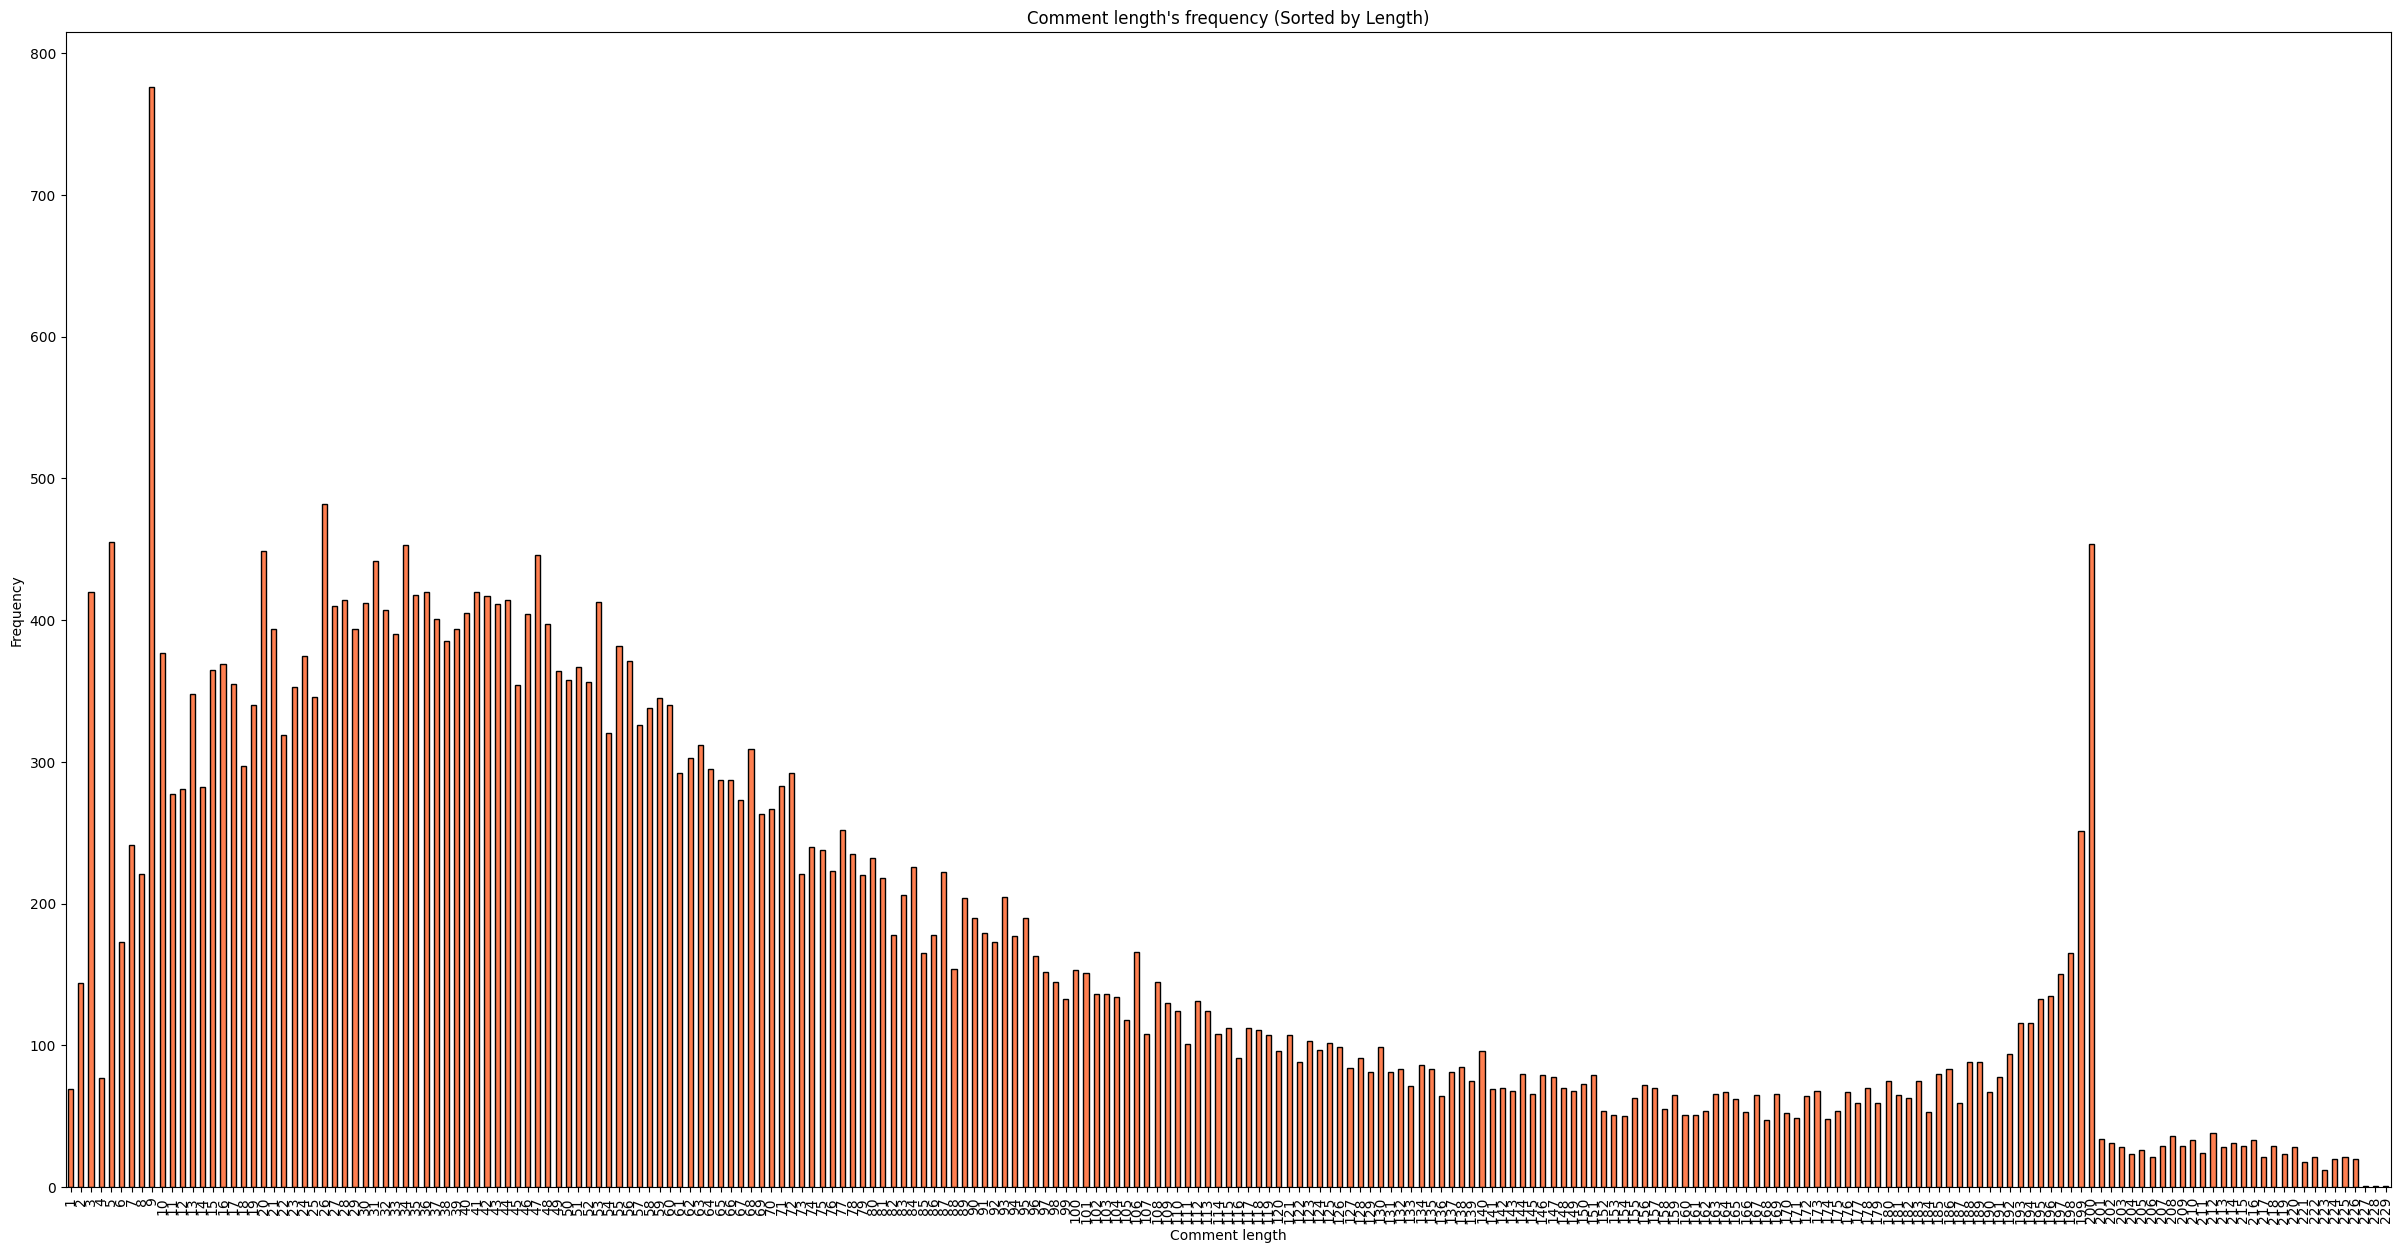

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(30, 15))
df['review_comment'].str.len().value_counts().sort_index().plot(kind='bar', color='coral', edgecolor='black')
plt.title("Comment length's frequency (Sorted by Length)")
plt.xlabel('Comment length')
plt.ylabel('Frequency')
plt.show()

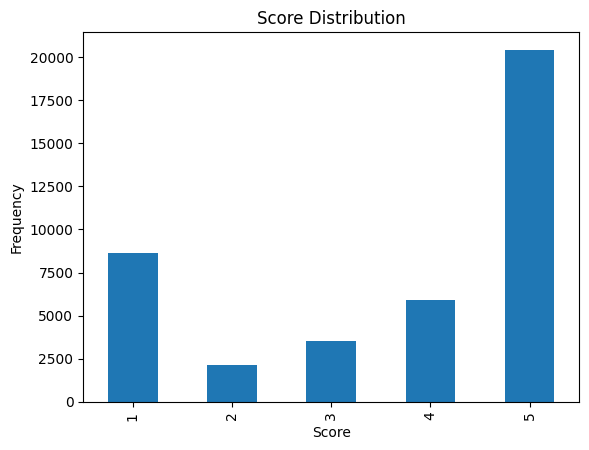

In [33]:
import matplotlib.pyplot as plt

df['review_score'].value_counts().sort_index().plot(kind='bar')
plt.title("Score Distribution")
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.show()

In [34]:
counts = df['review_score'].value_counts()
percentages = df['review_score'].value_counts(normalize=True) * 100

score_distribution = pd.DataFrame({'Count': counts, 'Percentage (%)': percentages})
display(score_distribution)

,Count,Percentage (%)
review_score,,
5,20413,50.236255
1,8640,21.262982
4,5935,14.605995
3,3528,8.682384
2,2118,5.212384


In [35]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
import numpy as np

X = df['review_comment'].values
y = (df['review_score'] - 1).values

# 80% train+val, 20% test (stratified by score)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 80% train, 20% validation
# 64% Train, 16% Val, 20% Test overall
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.20, random_state=42, stratify=y_temp
)

# Shuffle X_train and y_train while keeping them as separate arrays
shuffled_indices = np.random.permutation(len(X_train))
X_train = X_train[shuffled_indices]
y_train = y_train[shuffled_indices]

print("Train distribution:", np.bincount(y_train) / len(y_train))
print("Val distribution:  ", np.bincount(y_val) / len(y_val))
print("Test distribution: ", np.bincount(y_test) / len(y_test))

Train distribution: [0.21261296 0.05214382 0.08682946 0.14604884 0.50236493]
Val distribution:   [0.21270378 0.0521378  0.08674254 0.14610889 0.50230698]
Test distribution:  [0.21262458 0.05204873 0.08687092 0.14605636 0.50239941]


In [36]:
import zipfile
from pathlib import Path
from google.colab import files

export_dir = Path("/content/drive/MyDrive/NLP/splits")
export_dir.mkdir(parents=True, exist_ok=True)

for name, texts, labels in [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test)
]:
    split_df = pd.DataFrame({
        "review_comment": texts,
        "label": labels,           # 0–4
        "review_score": labels + 1 # 1–5
    })

    split_df.to_csv(
        export_dir / f"{name}.csv",
        index=False,
        encoding="utf-8-sig"
    )